In [4]:
%load_ext autoreload
%autoreload 2
import os

print(os.getcwd())

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
/home/users/v/vollert/TM-QA-combined


In [5]:
target = "TM-QA-combined"
cwd = os.getcwd()

# if current path already contains the target, jump to that segment
parts = cwd.split(os.sep)
if target in parts:
    os.chdir(os.sep.join(parts[: parts.index(target) + 1]) or os.sep)
else:
    # walk up to root to see if any parent is the target
    p = cwd
    found = False
    while True:
        if os.path.basename(p) == target:
            os.chdir(p)
            found = True
            break
        parent = os.path.dirname(p)
        if parent == p:
            break
        p = parent

    # if not found, search home directory
    if not found:
        for root, dirs, _ in os.walk(os.path.expanduser("~")):
            if target in dirs:
                os.chdir(os.path.join(root, target))
                found = True
                break

    if not found:
        raise FileNotFoundError(f"Could not find '{target}' from '{cwd}'")

print(os.getcwd())


from data.load_dataset import load_bioASQ
from models.load_reranker import load_reranker
from pprint import pp
import json
import numpy as np
from tqdm import tqdm
from models.finetuning.finetune_utils import build_training_pairs, train_epoch, RerankerDataset


/home/users/v/vollert/TM-QA-combined


/home/users/v/vollert/.conda/envs/tmqa/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [6]:
abstracts_path = "data/BioASQ-training14b/abstract_list_tokenized.json"
bioasq_path='data/BioASQ-training14b/training14b.json'
modelName = "ncbi/MedCPT-Cross-Encoder"


train_dataset, val_dataset, test_dataset, abstracts = load_bioASQ(
    abstracts_path=abstracts_path,
    bioasq_path=bioasq_path,
    train_ratio=0.8,
    val_ratio=0.1,
    test_ratio=0.1
)

Dataset loaded: 4582 train / 573 val / 573 test entries.
Entries dropped (no matching abstracts): 1


In [7]:
train_pool_path = "evaluation/train_pool.json"
test_pool_path = "evaluation/test_pool.json"
val_pool_path = "evaluation/val_pool.json"

with open(train_pool_path, "r", encoding="utf-8") as train_p_json:
        train_pool = json.load(train_p_json)
        
with open(test_pool_path, "r", encoding="utf-8") as test_p_json:
    test_pool = json.load(test_p_json)
        
with open(val_pool_path, "r", encoding="utf-8") as val_p_json:
    val_pool = json.load(val_p_json)

In [8]:
candidate = [item["candidates"] for item in train_pool]
candidateFlat = [cand for sublist in candidate for cand in sublist]
relevance_scores = [item["relevance_score"] for item in candidateFlat]

Count: 449826
Min: 0.0
Max: 1.0
Mean: 0.1565663451253806
Median: 0.0


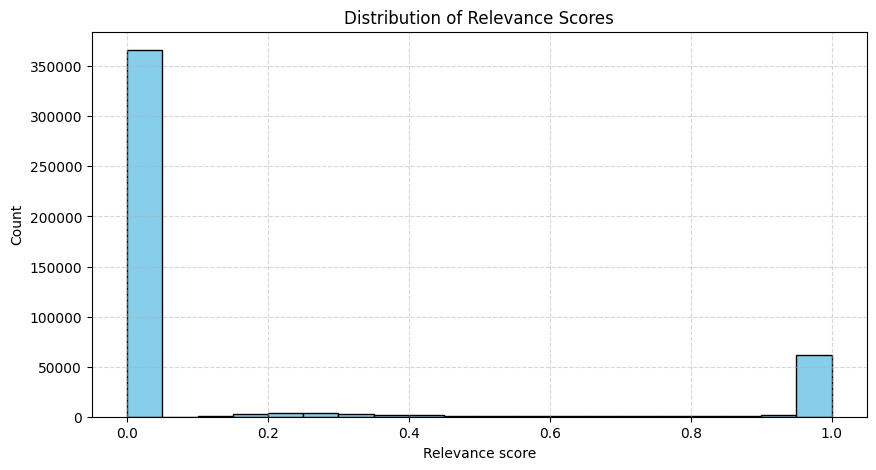

In [9]:
from statistics import mean, median

import matplotlib.pyplot as plt

print("Count:", len(relevance_scores))
print("Min:", min(relevance_scores))
print("Max:", max(relevance_scores))
print("Mean:", mean(relevance_scores))
print("Median:", median(relevance_scores))

plt.figure(figsize=(10, 5))
plt.hist(relevance_scores, bins=20, range=(0, 1), color="skyblue", edgecolor="black")
plt.title("Distribution of Relevance Scores")
plt.xlabel("Relevance score")
plt.ylabel("Count")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [10]:
def countRelevant(entry, threshold)->int:
    count = 0
    for e in entry:
        if e["relevance_score"] >threshold:
            count+=1
    return count

Count: 4582
Min: 0
Max: 201
Mean: 13.81492797904845
Median: 9.0


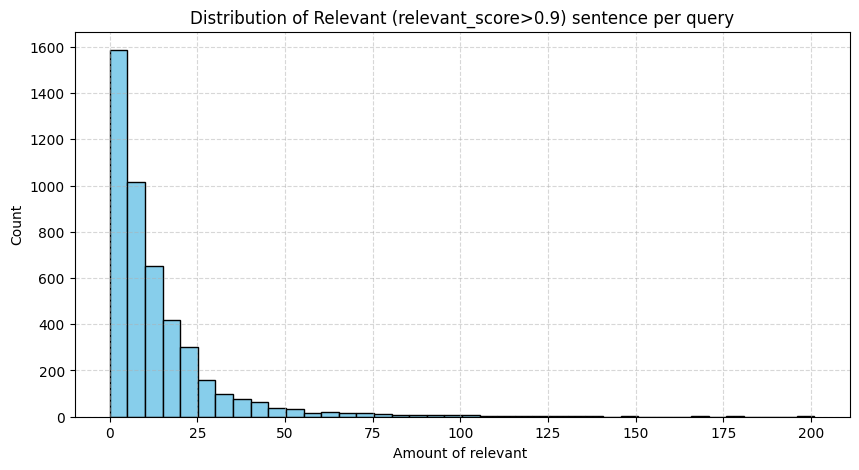

In [11]:
threshold = 0.9
relevancy = [countRelevant(item, threshold) for item in candidate]
print("Count:", len(relevancy))
print("Min:", min(relevancy))
print("Max:", max(relevancy))
print("Mean:", mean(relevancy))
print("Median:", median(relevancy))

plt.figure(figsize=(10, 5))
plt.hist(relevancy, bins=40, color="skyblue", edgecolor="black")
plt.title(f"Distribution of Relevant (relevant_score>{threshold}) sentence per query")
plt.xlabel("Amount of relevant ")
plt.ylabel("Count")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

What this show is that the problem of "too many relevant sentence per query" is not something that comes from a bad overlap scoring mechanism that would let through small, generic sentence. Adding a test on the minimum length of overlap to be considered relevant essentially binarized the distribution of relevant/not relevant, yet the average number of positive per query essentially did NOT change in the slightest. 

This mean the average relevant sentence with a score of, say, 0.9 is genuinely relevant, since it closely match the snippets. This leaves us with a problem still : some query haves too many positive sentences compared to the average, and we do not want them to completely overshadow the training data compared to the rest. 

This thus become a problem not of having noisy data (not particularly at least) but rather a problem of correctly balancing the data and sampling them in such a way they are balanced. 

In [12]:
len(candidate[np.argmax(relevancy)])

932

Count: 4582
Min: 1
Max: 1319
Mean: 98.17241379310344
Median: 59.0


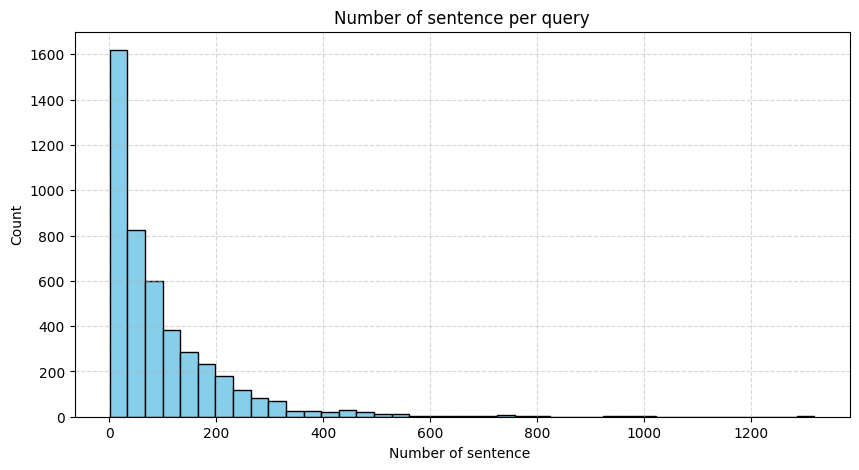

In [13]:
average_Num_SentencePerQuery = [len(item) for item in candidate]

print("Count:", len(average_Num_SentencePerQuery))
print("Min:", min(average_Num_SentencePerQuery))
print("Max:", max(average_Num_SentencePerQuery))
print("Mean:", mean(average_Num_SentencePerQuery))
print("Median:", median(average_Num_SentencePerQuery))

plt.figure(figsize=(10, 5))
plt.hist(average_Num_SentencePerQuery, bins=40, color="skyblue", edgecolor="black")
plt.title("Number of sentence per query")
plt.xlabel("Number of sentence ")
plt.ylabel("Count")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [14]:
countRelevant(candidate[np.argmax(average_Num_SentencePerQuery)], 0.9)

126

In [15]:
DEBUG_N = 10
pool_slice = train_pool if DEBUG_N is None else train_pool[:DEBUG_N]

In [16]:
model, tokenizer = load_reranker(
    model_path_or_name=modelName
)

Loading weights: 100%|███| 201/201 [00:00<00:00, 22446.15it/s]


Reranker loaded from 'ncbi/MedCPT-Cross-Encoder' on device 'cuda'.


In [17]:
threshold = 0.5
upper_margin = 0.2
lower_margin = 0.1
max_positives_per_query = 10
n_random_negatives = 3
n_hard_negatives = 2
batch_size = 16

all_training_pairs = []
skipped = 0
pairsCount =[]
for entry in tqdm(pool_slice, desc="Building training pairs"):
    pairs = build_training_pairs(
        pool_entry=entry,
        model=model,
        tokenizer=tokenizer,
        threshold=threshold,
        upper_margin=upper_margin,
        lower_margin=lower_margin,
        max_positives_per_query=max_positives_per_query,
        n_random_negatives=n_random_negatives,
        n_hard_negatives=n_hard_negatives,
        batch_size=batch_size
    )
    if not pairs:
        skipped += 1
    all_training_pairs.extend(pairs)
    pairsCount.append(len(pairs))

print(f"Total training pairs: {len(all_training_pairs)}")
print(f"Queries contributing zero pairs: {skipped}/{len(pool_slice)}")

Building training pairs: 100%|█| 10/10 [00:04<00:00,  2.07it/s

Total training pairs: 420
Queries contributing zero pairs: 0/10


In [18]:
pp(all_training_pairs[50:60])

[{'query': 'What 3 organs are the sphincter of Oddi associated with?',
  'positive': 'The most common functional disorder of the biliary tract and '
              'pancreas relates to the activity of the Sphincter of Oddi.',
  'negative': 'Data from animal and human studies, using sensitive techniques, '
              'have helped define the physiological role of the sphincter of '
              'Oddi, and more recent studies are determining the factors which '
              'control sphincter of Oddi function.'},
 {'query': 'What 3 organs are the sphincter of Oddi associated with?',
  'positive': 'The most common functional disorder of the biliary tract and '
              'pancreas relates to the activity of the Sphincter of Oddi.',
  'negative': 'The structure of the sphincter of Oddi differs from species to '
              'species and consequently its physiological action varies in '
              'different species.'},
 {'query': 'What 3 organs are the sphincter of Oddi associate

Count: 10
Min: 20
Max: 50
Mean: 42
Median: 47.5


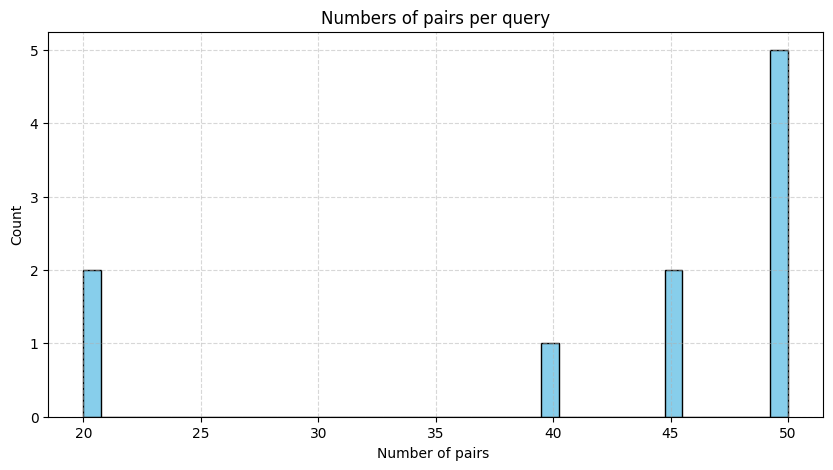

In [19]:
print("Count:", len(pairsCount))
print("Min:", min(pairsCount))
print("Max:", max(pairsCount))
print("Mean:", mean(pairsCount))
print("Median:", median(pairsCount))

plt.figure(figsize=(10, 5))
plt.hist(pairsCount, bins=40, color="skyblue", edgecolor="black")
plt.title("Numbers of pairs per query")
plt.xlabel("Number of pairs ")
plt.ylabel("Count")
plt.grid(True, linestyle="--", alpha=0.5)
plt.show()

In [20]:
len(all_training_pairs)

420

In [21]:
dataset = RerankerDataset(all_training_pairs)

In [ ]:
train_epoch(
    model=model,
    dataloader=dataset,
    optimizer=None,
    scheduler=None,
    margin=None,
    max_grad_norm=None
)

In [32]:
from datasets import load_dataset

ds = load_dataset(path="qiaojin/PubMedQA", name="pqa_artificial", split="train")

In [26]:
ids = [item['pubid'] for item in ds['train']]

In [34]:
ds[0]

{'pubid': 25429730,
 'question': 'Are group 2 innate lymphoid cells ( ILC2s ) increased in chronic rhinosinusitis with nasal polyps or eosinophilia?',
 'context': {'contexts': ['Chronic rhinosinusitis (CRS) is a heterogeneous disease with an uncertain pathogenesis. Group 2 innate lymphoid cells (ILC2s) represent a recently discovered cell population which has been implicated in driving Th2 inflammation in CRS; however, their relationship with clinical disease characteristics has yet to be investigated.',
   'The aim of this study was to identify ILC2s in sinus mucosa in patients with CRS and controls and compare ILC2s across characteristics of disease.',
   'A cross-sectional study of patients with CRS undergoing endoscopic sinus surgery was conducted. Sinus mucosal biopsies were obtained during surgery and control tissue from patients undergoing pituitary tumour resection through transphenoidal approach. ILC2s were identified as CD45(+) Lin(-) CD127(+) CD4(-) CD8(-) CRTH2(CD294)(+) CD

In [28]:
len(ids)

211269

In [29]:
idsUnique = set(ids)
len(idsUnique)

211269